<a href="https://colab.research.google.com/github/seabass6969/audio-ml-group-project/blob/master/Audio_ML_course_collaboration_Notebooks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Audio ML course group project
## The goal:
Dogs and Cats Classification

## Import library and download dataset

Run the code below before you start working on things.
This will download the dataset and also import the library

### Download the datasets

In [ ]:
# Download the dataset
import kagglehub

path = kagglehub.dataset_download("stealthtechnologies/cats-vs-dogs-audio-classification")
path = path + "/DvC/"
print(path)

100%|██████████| 130M/130M [00:01<00:00, 69.1MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/stealthtechnologies/cats-vs-dogs-audio-classification/versions/2/DvC/


In [ ]:
!pip install gitpython
from git import Repo  # pip install gitpython
import os
try:
  os.mkdir("/data_set/")
  Repo.clone_from("https://github.com/karolpiczak/ESC-50", "/data_set/")
except:
  print("directory already existed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gitpython]


### Import the library

In [ ]:
# import the library
import librosa
import soundfile as sf
import IPython
from glob import glob
import sklearn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Load the alternative dataset sound files

In [ ]:
df = pd.read_csv("/data_set/meta/esc50.csv")

alt_dog_list = ["/data_set/audio/"+file for file in df[df["category"] == "dog"]["filename"]]
alt_cat_list = ["/data_set/audio/"+file for file in df[df["category"] == "cat"]["filename"]]

alt_no_cat = df[df["category"] != "cat"]
alt_no_cat_dog = alt_no_cat[alt_no_cat["category"] != "dog"]
# making categories of the dataset to perform stratfy sampling
alt_junk_dict = {}



alt_junk_list = ["/data_set/audio/"+file for file in alt_no_cat_dog["filename"]]

## Load the sound file

In [ ]:
cat_file_list = glob(path + "Cats/*")
dog_file_list = glob(path + "Dogs/*")

In [ ]:
# tests if the audio loads or not
print("Cat Audio :3")
y, sr = librosa.load(path + "Cats/" + "cat0001.wav", mono=True, sr=None)
IPython.display.Audio(data=y, rate=sr)

Cat Audio :3


Here is some examples of the plots. This will be useful when I am explaining what features that we are extracting from the audio files.

### Example of Cats

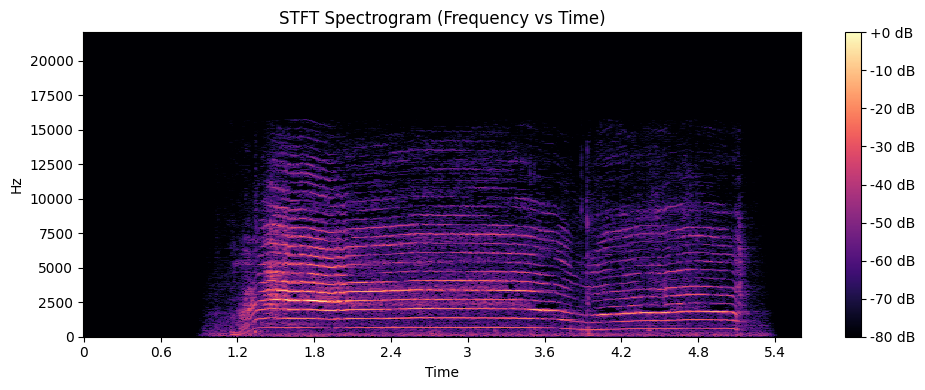

In [ ]:
# The plot of one of the spectrogram
y, sr = librosa.load(path + "Cats/" + "cat0001.wav", mono=True, sr=None)

stft_matrix = librosa.stft(y)

stft_db = librosa.amplitude_to_db(np.abs(stft_matrix), ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='hz')

plt.colorbar(format='%+2.0f dB')
plt.title('STFT Spectrogram (Frequency vs Time)')
plt.tight_layout()
plt.show()

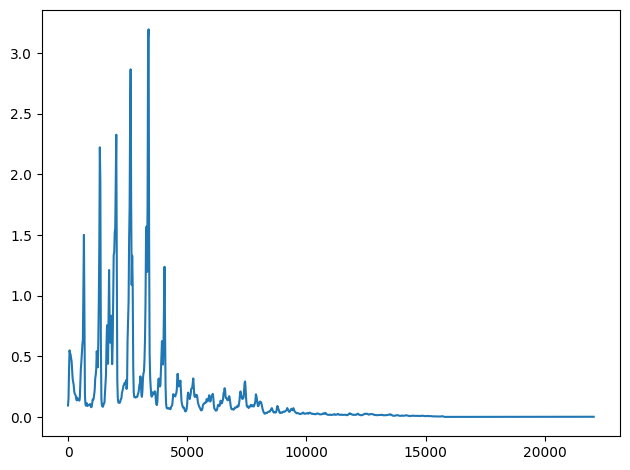

In [ ]:
# plot of the features that we could be extracting
y, sr = librosa.load(path + "Cats/" + "cat0001.wav", mono=True, sr=None)

n_fft = 2048
hop_length = 512

stft_matrix = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
stft_amplitudes = np.abs(stft_matrix)
mean_amplitudes = np.mean(stft_amplitudes, axis=1)

frequencies = librosa.fft_frequencies(sr=sr, n_fft=n_fft)

plt.plot(frequencies, mean_amplitudes)

plt.tight_layout()
plt.show()

### Example of Dogs

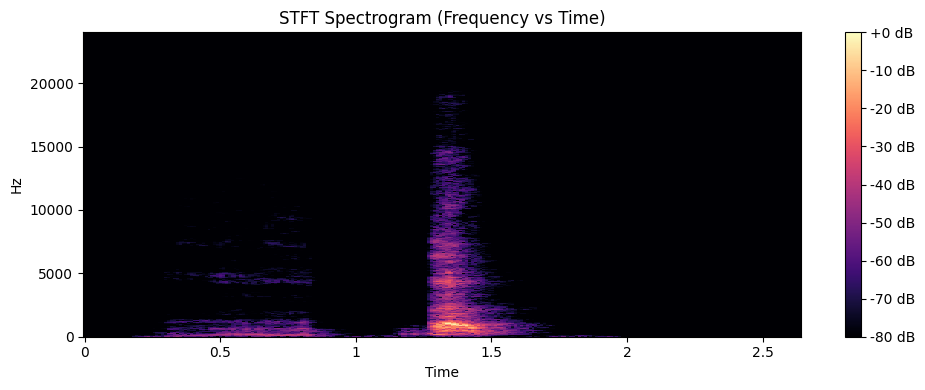

In [ ]:
# The plot of one of the spectrogram
y, sr = librosa.load(path + "Dogs/" + "dog0001.wav", mono=True, sr=None)

stft_matrix = librosa.stft(y)

stft_db = librosa.amplitude_to_db(np.abs(stft_matrix), ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='hz')

plt.colorbar(format='%+2.0f dB')
plt.title('STFT Spectrogram (Frequency vs Time)')
plt.tight_layout()
plt.show()

## Extract Features from audio file

### Extract by getting the overall frequency of it

In [ ]:
def extract_features_from_audio_file(paths: str, ):
  y, sr = librosa.load(paths, mono=True, sr=None)

  n_fft = 2048
  hop_length = 512

  stft_matrix = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
  stft_amplitudes = np.abs(stft_matrix)
  mean_amplitudes = np.mean(stft_amplitudes, axis=1)
  max_val = np.max(mean_amplitudes)
  if max_val > 0:
  # This is to normalise the value for everything back to 1 to 0 for easier process in the future
    return mean_amplitudes / max_val
  return mean_amplitudes

X = []
y = []
label_type = {1: "dog", 0: "cat"}
for cat in cat_file_list:
  if cat.endswith(".wav"):
    X.append(extract_features_from_audio_file(cat))
    y.append(0)
for dog in dog_file_list:
  if dog.endswith(".wav"):
    X.append(extract_features_from_audio_file(dog))
    y.append(1)
X = np.array(X)
y = np.array(y)


### Extract the alt dataset

In [ ]:
X_alt = []
y_alt = []
for cat in alt_cat_list:
  X_alt.append(extract_features_from_audio_file(cat))
  y_alt.append(0)
for dog in alt_dog_list:
  X_alt.append(extract_features_from_audio_file(dog))
  y_alt.append(1)

X_alt, X_half, y_alt, y_half = sklearn.model_selection.train_test_split(X_alt,y_alt, test_size=0.4, shuffle=True)

In [ ]:
# we are doing a 60 20 20 split for the train test validation
X_train, X_s, y_train, y_s = sklearn.model_selection.train_test_split(X,y, test_size=0.4, shuffle=True)
X_test, X_val, y_test, y_val = sklearn.model_selection.train_test_split(X_s,y_s, test_size=0.5, shuffle=True)

## Model

### Logistic Regression

In [ ]:
# LogisticRegression
model = sklearn.linear_model.LogisticRegression()
model.fit(X_train, y_train)


y_pred_val_LR = model.predict(X_val)
# print(y_[y_pred_val_LR != y_val])


In [ ]:
y_pred_alt = model.predict(X_alt)
sklearn.metrics.accuracy_score(y_alt, y_pred_alt)

0.8125

## Accuracy and Metrics

In [ ]:
sklearn.metrics.accuracy_score(y_val, y_pred_val_LR)

0.9714285714285714

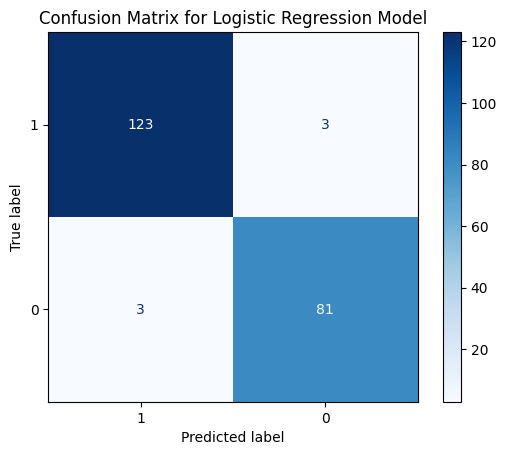

In [ ]:
#confusion matrix
cm = sklearn.metrics.confusion_matrix(y_val, y_pred_val_LR)
disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_type.keys())
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Logistic Regression Model')
plt.show()
#print("\nConfusion matrix:\n",cm)

### K-NN

In [ ]:
best_validation_accuracy=-1.0
best_k=None
validation_accuracies = []
training_accuracies = []
k_nums = []
for k in [1,3,5,7,9,10,12,15]:
    knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    training_accuracy = knn.score(X_train, y_train)
    y_pred_val = knn.predict(X_val)
    validation_accuracy = sklearn.metrics.accuracy_score(y_val, y_pred_val)
    #print(f"knn: {validation_accuracy=},{training_accuracy=},{k=}")
    validation_accuracies.append(validation_accuracy)
    training_accuracies.append(training_accuracy)
    k_nums.append(k)
    if validation_accuracy > best_validation_accuracy:
        # save model when it beats the current best
        best_validation_accuracy = validation_accuracy
        best_k = k
        best_knn = knn
        best_knn_training_accuracy = training_accuracy

# evaluate best k-nn on the held out test set
y_pred_test_knn = best_knn.predict(X_test)
test_accuracy = sklearn.metrics.accuracy_score(y_test, y_pred_test_knn)


knn: validation accuracy=0.9333333333333333, training accuracy=1.0,k=1
knn: validation accuracy=0.9333333333333333, training accuracy=0.9841269841269841,k=3
knn: validation accuracy=0.9428571428571428, training accuracy=0.9682539682539683,k=5
knn: validation accuracy=0.9428571428571428, training accuracy=0.9571428571428572,k=7
knn: validation accuracy=0.9476190476190476, training accuracy=0.9507936507936507,k=9
knn: validation accuracy=0.9476190476190476, training accuracy=0.9555555555555556,k=10
knn: validation accuracy=0.9428571428571428, training accuracy=0.9507936507936507,k=12
knn: validation accuracy=0.9380952380952381, training accuracy=0.9412698412698413,k=15


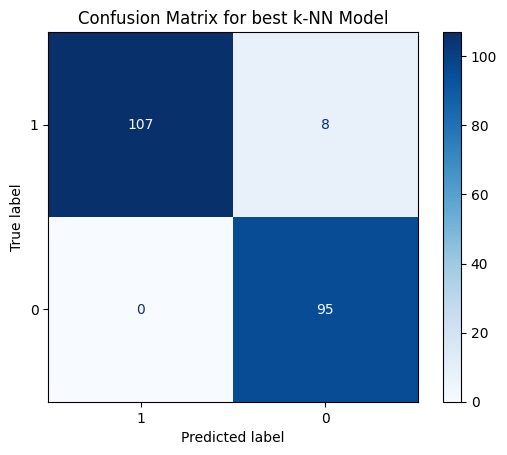

best_k=9,best_validation_accuracy=0.9476190476190476,best_knn_training_accuracy=0.9507936507936507
Test accuracy for best k-NN model: 0.9619047619047619


In [ ]:
for i in range(len(k_nums)):
  print(f"knn: validation accuracy={validation_accuracies[i]}, training accuracy={training_accuracies[i]},k={k_nums[i]}")
# confusion matrix on test set
best_knn_confusion_matrix = sklearn.metrics.confusion_matrix(y_test, y_pred_test_knn)
disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=best_knn_confusion_matrix, display_labels=label_type.keys())
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for best k-NN Model')
plt.show()

print(f"{best_k=},{best_validation_accuracy=},{best_knn_training_accuracy=}")
print(f"Test accuracy for best k-NN model: {test_accuracy}")